In [3]:

#Loading the Feature Engineered Dataset

import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/feature_engineered_100k.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (100000, 24)


,job_level,age,years_at_company,monthly_income,overtime,job_satisfaction,performance_rating,distance_from_home_km,years_since_promotion,attrition,...,department_Marketing,department_Operations,department_Research,department_Sales,work_mode_Hybrid,work_mode_Onsite,work_mode_Remote,hire_year,promotion_tenure_ratio,overtime_tenure
0,4,38,11,9700,1,3,4,15.0,10,0,...,0,0,0,0,0,1,0,2015,0.909091,11
1,5,64,11,16710,1,4,4,19.0,1,0,...,0,0,1,0,0,1,0,2015,0.090909,11
2,3,55,11,8280,1,4,3,8.0,0,0,...,0,0,0,0,1,0,0,2015,0.000000,11
3,4,39,11,10050,0,1,5,4.0,0,0,...,0,0,0,1,1,0,0,2015,0.000000,0
4,3,44,11,7860,1,3,4,4.0,0,0,...,0,1,0,0,1,0,0,2015,0.000000,11


In [4]:
#Verify the dataset

print("Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["attrition"].value_counts())

Columns:
['job_level', 'age', 'years_at_company', 'monthly_income', 'overtime', 'job_satisfaction', 'performance_rating', 'distance_from_home_km', 'years_since_promotion', 'attrition', 'department_Customer Support', 'department_Engineering', 'department_Finance', 'department_Human Resources', 'department_Marketing', 'department_Operations', 'department_Research', 'department_Sales', 'work_mode_Hybrid', 'work_mode_Onsite', 'work_mode_Remote', 'hire_year', 'promotion_tenure_ratio', 'overtime_tenure']

Missing Values:
job_level                          0
age                                0
years_at_company                   0
monthly_income                     0
overtime                           0
job_satisfaction                   0
performance_rating                 0
distance_from_home_km          17225
years_since_promotion              0
attrition                          0
department_Customer Support        0
department_Engineering             0
department_Finance                 

In [5]:
import sys
print(sys.executable)

c:\Users\Lenovo\Desktop\AttriSense\job-attrition\.venv\Scripts\python.exe


In [6]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [7]:
import sklearn
print(sklearn.__version__)

1.9.0


In [8]:
#Import libraries

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
#Load the feature-engineered dataset

df = pd.read_csv("../data/processed/feature_engineered_100k.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (100000, 24)


,job_level,age,years_at_company,monthly_income,overtime,job_satisfaction,performance_rating,distance_from_home_km,years_since_promotion,attrition,...,department_Marketing,department_Operations,department_Research,department_Sales,work_mode_Hybrid,work_mode_Onsite,work_mode_Remote,hire_year,promotion_tenure_ratio,overtime_tenure
0,4,38,11,9700,1,3,4,15.0,10,0,...,0,0,0,0,0,1,0,2015,0.909091,11
1,5,64,11,16710,1,4,4,19.0,1,0,...,0,0,1,0,0,1,0,2015,0.090909,11
2,3,55,11,8280,1,4,3,8.0,0,0,...,0,0,0,0,1,0,0,2015,0.000000,11
3,4,39,11,10050,0,1,5,4.0,0,0,...,0,0,0,1,1,0,0,2015,0.000000,0
4,3,44,11,7860,1,3,4,4.0,0,0,...,0,1,0,0,1,0,0,2015,0.000000,11


In [10]:
#Check the target distribution

print(df["attrition"].value_counts())

print("\nPercentage distribution:")
print(df["attrition"].value_counts(normalize=True) * 100)

attrition
0    83072
1    16928
Name: count, dtype: int64

Percentage distribution:
attrition
0    83.072
1    16.928
Name: proportion, dtype: float64


In [11]:
#Separate X and y

X = df.drop("attrition", axis=1)
y = df["attrition"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100000, 23)
y shape: (100000,)


In [12]:
#Perform train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80000, 23)
Testing data: (20000, 23)


In [13]:
#Verify class distribution

print("Original distribution:")
print(y.value_counts(normalize=True) * 100)

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

Original distribution:
attrition
0    83.072
1    16.928
Name: proportion, dtype: float64

Training distribution:
attrition
0    83.0725
1    16.9275
Name: proportion, dtype: float64

Testing distribution:
attrition
0    83.07
1    16.93
Name: proportion, dtype: float64


In [14]:
from sklearn.tree import DecisionTreeClassifier

In [15]:
#Import preprocessing tools

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [16]:
#Create Logistic Regression pipeline

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [17]:
#Train Logistic Regression
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [62]:

import joblib
import os

# Select 100 representative training records
X_background = X_train_new.sample(
    n=min(100, len(X_train_new)),
    random_state=42
)

# Apply the same preprocessing used by the model
X_background = logistic_model.named_steps["imputer"].transform(
    X_background
)

X_background = logistic_model.named_steps["scaler"].transform(
    X_background
)

# Load the existing model bundle
model_path = "../models/attrisense_model.pkl"
model_bundle = joblib.load(model_path)

# Add SHAP background data
model_bundle["background_data"] = X_background

# Save the updated bundle
joblib.dump(model_bundle, model_path)

print("Updated model bundle successfully!")
print("Available keys:", model_bundle.keys())


Updated model bundle successfully!
Available keys: dict_keys(['model', 'threshold', 'features', 'background_data'])


In [18]:
#Generate predictions

y_pred_lr = logistic_model.predict(X_test)

print(y_pred_lr[:10])

[0 0 0 0 0 0 0 1 0 0]


In [19]:
# Evaluate Logistic Regression

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression
Accuracy: 0.9036

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.94     16614
           1       0.87      0.51      0.64      3386

    accuracy                           0.90     20000
   macro avg       0.89      0.75      0.79     20000
weighted avg       0.90      0.90      0.89     20000


Confusion Matrix:
[[16361   253]
 [ 1675  1711]]


In [22]:
#Create the model
random_forest = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [23]:
#Train Random Forest
random_forest.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [24]:
#Generate predictions

y_pred_rf = random_forest.predict(X_test)

print(y_pred_rf[:10])

[0 0 0 0 0 0 0 1 0 0]


In [25]:
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("Logistic predictions:", len(y_pred_lr))
print("Random Forest predictions:", len(y_pred_rf))

X_test: (20000, 23)
y_test: (20000,)
Logistic predictions: 20000
Random Forest predictions: 20000


In [26]:
# Evaluate Random Forest

print("Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest
Accuracy: 0.8799

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.98      0.93     16614
           1       0.83      0.37      0.51      3386

    accuracy                           0.88     20000
   macro avg       0.86      0.68      0.72     20000
weighted avg       0.87      0.88      0.86     20000


Confusion Matrix:
[[16360   254]
 [ 2148  1238]]


In [27]:
# Initialize Decision Tree

decision_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=10,
        random_state=42
    ))
])

# Train the model
decision_tree.fit(X_train, y_train)

# Generate predictions
y_pred_dt = decision_tree.predict(X_test)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [28]:
print("Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree
Accuracy: 0.8698

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.99      0.93     16614
           1       0.81      0.30      0.44      3386

    accuracy                           0.87     20000
   macro avg       0.84      0.64      0.68     20000
weighted avg       0.86      0.87      0.84     20000


Confusion Matrix:
[[16372   242]
 [ 2362  1024]]


In [29]:
from sklearn.ensemble import GradientBoostingClassifier

In [30]:
# Initialize Gradient Boosting

gradient_boosting = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gradient_boosting.fit(X_train, y_train)

# Generate predictions
y_pred_gb = gradient_boosting.predict(X_test)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [31]:
print("Gradient Boosting")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

Gradient Boosting
Accuracy: 0.9033

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.94     16614
           1       0.96      0.45      0.61      3386

    accuracy                           0.90     20000
   macro avg       0.93      0.72      0.78     20000
weighted avg       0.91      0.90      0.89     20000


Confusion Matrix:
[[16557    57]
 [ 1877  1509]]


In [32]:
# Generate prediction probabilities for all models

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]
y_prob_dt = decision_tree.predict_proba(X_test)[:, 1]
y_prob_gb = gradient_boosting.predict_proba(X_test)[:, 1]

# Compare ROC-AUC scores

models = {
    "Logistic Regression": y_prob_lr,
    "Random Forest": y_prob_rf,
    "Decision Tree": y_prob_dt,
    "Gradient Boosting": y_prob_gb
}

for name, probabilities in models.items():
    score = roc_auc_score(y_test, probabilities)
    print(f"{name}: {score:.4f}")

Logistic Regression: 0.8898
Random Forest: 0.8485
Decision Tree: 0.8223
Gradient Boosting: 0.8854


In [33]:
thresholds = [0.3, 0.35, 0.4, 0.45, 0.5]

for threshold in thresholds:
    y_pred = (y_prob_lr >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print(classification_report(
        y_test,
        y_pred,
        output_dict=False
    ))


Threshold: 0.3
              precision    recall  f1-score   support

           0       0.93      0.92      0.93     16614
           1       0.63      0.66      0.65      3386

    accuracy                           0.88     20000
   macro avg       0.78      0.79      0.79     20000
weighted avg       0.88      0.88      0.88     20000


Threshold: 0.35
              precision    recall  f1-score   support

           0       0.92      0.95      0.93     16614
           1       0.70      0.62      0.66      3386

    accuracy                           0.89     20000
   macro avg       0.81      0.78      0.80     20000
weighted avg       0.89      0.89      0.89     20000


Threshold: 0.4
              precision    recall  f1-score   support

           0       0.92      0.96      0.94     16614
           1       0.76      0.58      0.66      3386

    accuracy                           0.90     20000
   macro avg       0.84      0.77      0.80     20000
weighted avg       0.89  

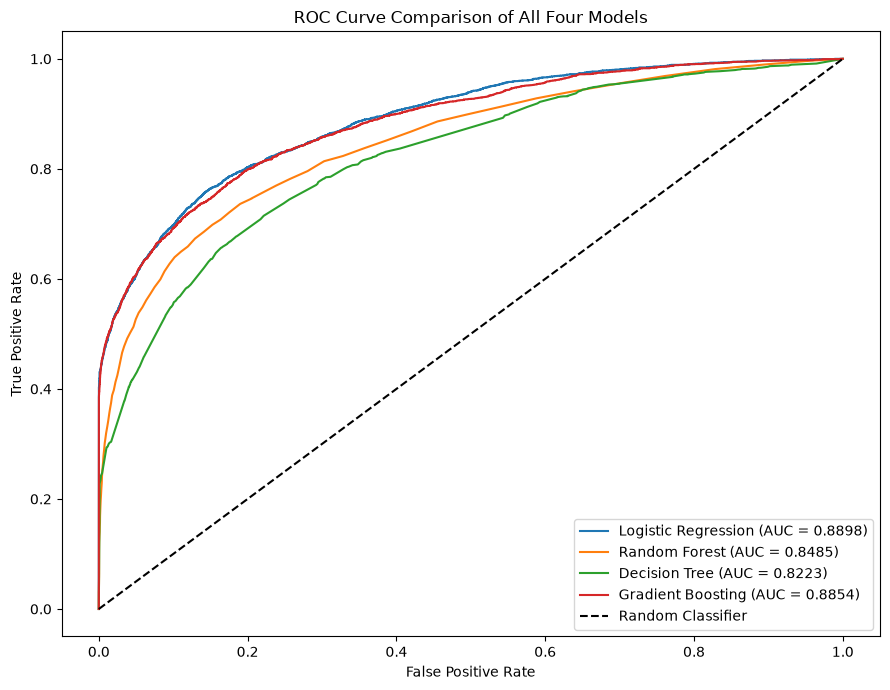

In [34]:
plt.figure(figsize=(9, 7))

for name, probabilities in models.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of All Four Models")

plt.legend()
plt.tight_layout()
plt.show()

In [35]:
# Extract feature importance from Random Forest

importances = random_forest.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
20,hire_year,0.155760
3,monthly_income,0.149299
1,age,0.118202
7,distance_from_home_km,0.112553
2,years_at_company,0.076585
5,job_satisfaction,0.054734
6,performance_rating,0.053288
21,promotion_tenure_ratio,0.042832
22,overtime_tenure,0.040867
8,years_since_promotion,0.033984


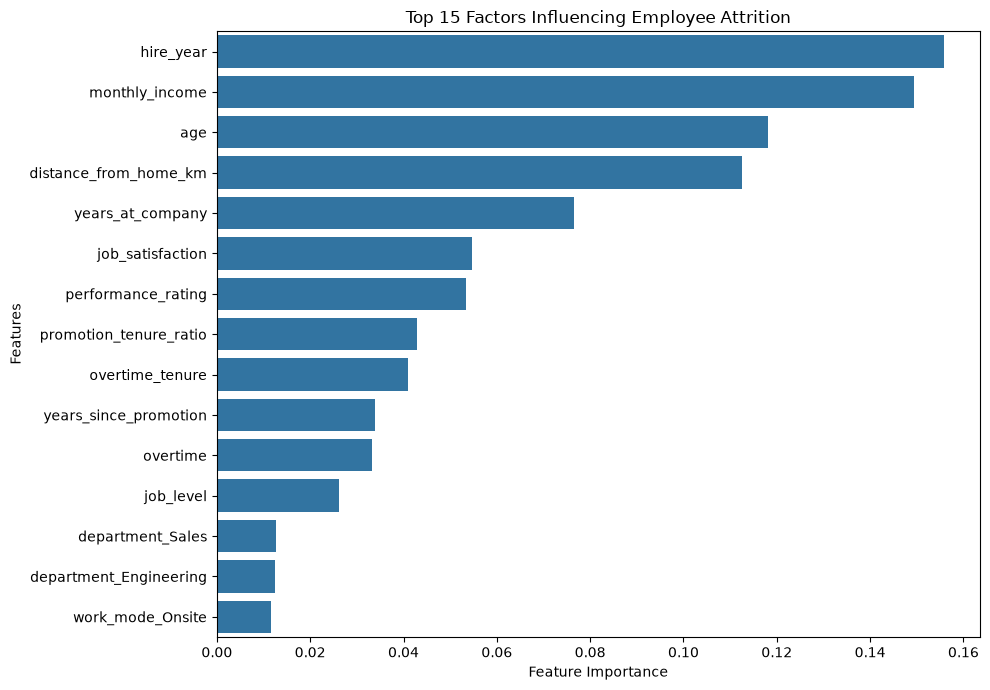

In [36]:
# Plot top 15 important features

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Factors Influencing Employee Attrition")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [37]:
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [38]:
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train_new, y_train_new)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['job_level','age','years_at_company',...,'hire_year', 'promotion_tenure_ratio','overtime_tenure']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_

In [39]:
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

In [40]:
thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(classification_report(
        y_val,
        y_val_pred,
        zero_division=0
    ))


Threshold: 0.25
              precision    recall  f1-score   support

           0       0.94      0.89      0.91     13292
           1       0.57      0.71      0.63      2708

    accuracy                           0.86     16000
   macro avg       0.75      0.80      0.77     16000
weighted avg       0.88      0.86      0.87     16000


Threshold: 0.3
              precision    recall  f1-score   support

           0       0.93      0.92      0.93     13292
           1       0.63      0.66      0.64      2708

    accuracy                           0.88     16000
   macro avg       0.78      0.79      0.78     16000
weighted avg       0.88      0.88      0.88     16000


Threshold: 0.35
              precision    recall  f1-score   support

           0       0.92      0.95      0.93     13292
           1       0.70      0.61      0.65      2708

    accuracy                           0.89     16000
   macro avg       0.81      0.78      0.79     16000
weighted avg       0.88 

In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_val, y_val_pred):.3f} | "
        f"Recall: {recall_score(y_val, y_val_pred):.3f} | "
        f"F1: {f1_score(y_val, y_val_pred):.3f}"
    )

Threshold: 0.25 | Precision: 0.571 | Recall: 0.711 | F1: 0.633
Threshold: 0.30 | Precision: 0.628 | Recall: 0.657 | F1: 0.642
Threshold: 0.35 | Precision: 0.699 | Recall: 0.607 | F1: 0.650
Threshold: 0.40 | Precision: 0.763 | Recall: 0.573 | F1: 0.655
Threshold: 0.45 | Precision: 0.826 | Recall: 0.537 | F1: 0.651
Threshold: 0.50 | Precision: 0.880 | Recall: 0.503 | F1: 0.640


In [42]:
#Evaluating the model on the test set with the selected threshold

y_test_prob = logistic_model.predict_proba(X_test)[:, 1]

final_threshold = 0.40

y_test_pred = (y_test_prob >= final_threshold).astype(int)

print("Final Model: Logistic Regression")
print("Threshold:", final_threshold)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

Final Model: Logistic Regression
Threshold: 0.4

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.96      0.94     16614
           1       0.76      0.58      0.66      3386

    accuracy                           0.90     20000
   macro avg       0.84      0.77      0.80     20000
weighted avg       0.89      0.90      0.89     20000

Confusion Matrix:
[[15992   622]
 [ 1428  1958]]
ROC-AUC: 0.8898425107213573


In [43]:
#Feature Importance

In [44]:
classifier = logistic_model.named_steps["classifier"]

coefficients = classifier.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": X_train_new.columns,
    "Coefficient": coefficients
})

feature_importance["Abs_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Abs_Coefficient",
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient,Abs_Coefficient
2,years_at_company,-9.827646,9.827646
20,hire_year,-9.298100,9.298100
4,overtime,0.456765,0.456765
5,job_satisfaction,-0.443911,0.443911
8,years_since_promotion,0.289933,0.289933
3,monthly_income,-0.264104,0.264104
0,job_level,0.251580,0.251580
7,distance_from_home_km,0.222148,0.222148
21,promotion_tenure_ratio,-0.109909,0.109909
19,work_mode_Remote,-0.107109,0.107109


In [45]:
X_train_reduced = X_train_new.drop("hire_year", axis=1)
X_val_reduced = X_val.drop("hire_year", axis=1)
X_test_reduced = X_test.drop("hire_year", axis=1)

In [46]:
logistic_model_reduced = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model_reduced.fit(X_train_reduced, y_train_new)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['job_level','age','years_at_company',...,'work_mode_Remote', 'promotion_tenure_ratio','overtime_tenure']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of m

In [47]:
# Generate predictions on the validation set
y_val_prob_reduced = logistic_model_reduced.predict_proba(X_val_reduced)[:, 1]

y_val_pred_reduced = (y_val_prob_reduced >= 0.40).astype(int)

print(classification_report(y_val, y_val_pred_reduced))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_reduced))

              precision    recall  f1-score   support

           0       0.86      0.95      0.90     13292
           1       0.49      0.25      0.33      2708

    accuracy                           0.83     16000
   macro avg       0.68      0.60      0.62     16000
weighted avg       0.80      0.83      0.80     16000

ROC-AUC: 0.7528019097014631


In [48]:
print(
    df[["hire_year", "years_at_company"]].corr()
)

                  hire_year  years_at_company
hire_year          1.000000         -0.979177
years_at_company  -0.979177          1.000000


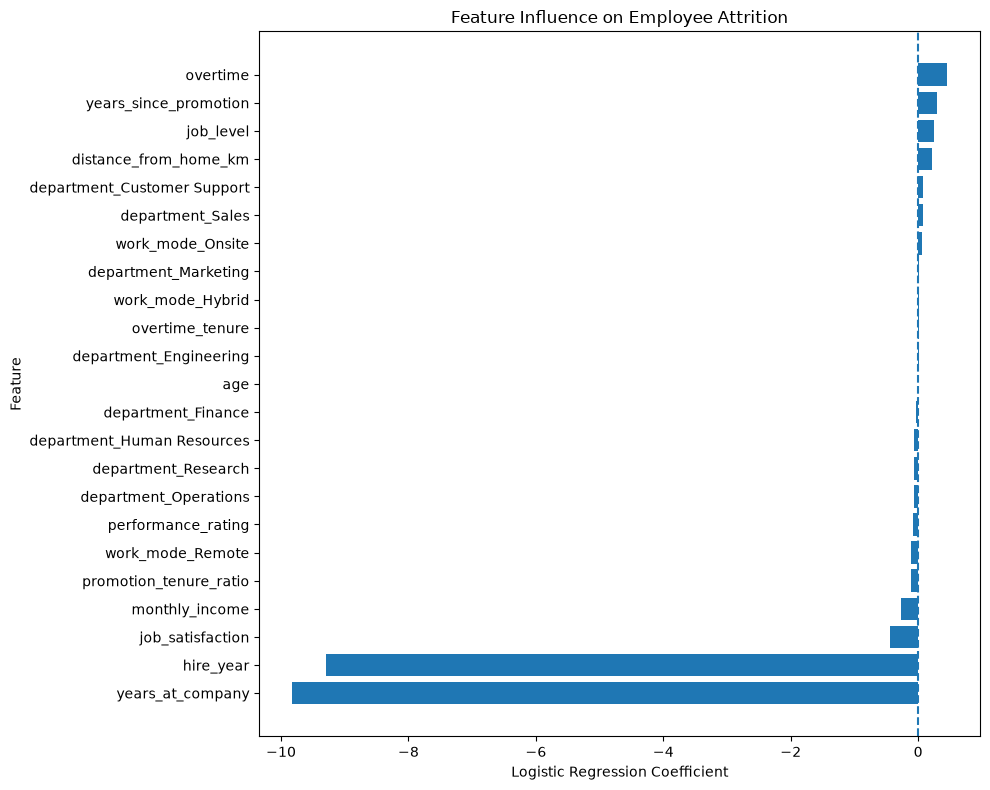

In [49]:
feature_importance_lr = pd.DataFrame({
    "Feature": X_train_new.columns,
    "Coefficient": logistic_model.named_steps["classifier"].coef_[0]
})

feature_importance_lr = feature_importance_lr.sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance_lr["Feature"],
    feature_importance_lr["Coefficient"]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Feature Influence on Employee Attrition")

plt.tight_layout()
plt.show()

In [50]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [51]:
import shap

explainer = shap.LinearExplainer(
    logistic_model.named_steps["classifier"],
    logistic_model.named_steps["scaler"].transform(
        logistic_model.named_steps["imputer"].transform(X_train_new)
    )
)

Background dataset has 64000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=64000 when initializing the masker.


In [52]:
shap_values = explainer.shap_values(
    logistic_model.named_steps["scaler"].transform(
        logistic_model.named_steps["imputer"].transform(X_val)
    )
)

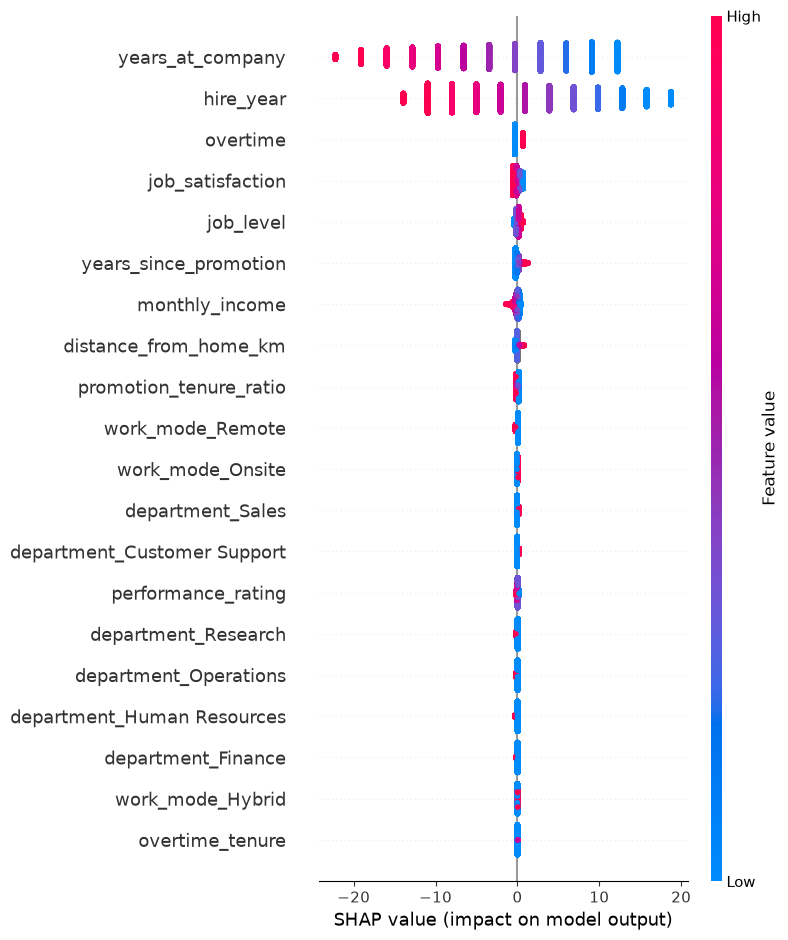

In [53]:
shap.summary_plot(
    shap_values,
    X_val,
    feature_names=X_val.columns
)

In [54]:
shap_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Mean_SHAP_Value": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_SHAP_Value",
    ascending=False
)

print(shap_importance.head(15))

                        Feature  Mean_SHAP_Value
2              years_at_company         8.373716
20                    hire_year         7.956377
4                      overtime         0.425077
5              job_satisfaction         0.389707
0                     job_level         0.220301
8         years_since_promotion         0.206163
3                monthly_income         0.199904
7         distance_from_home_km         0.173347
21       promotion_tenure_ratio         0.096783
19             work_mode_Remote         0.082691
18             work_mode_Onsite         0.066612
16             department_Sales         0.064444
9   department_Customer Support         0.062844
6            performance_rating         0.060702
15          department_Research         0.048503


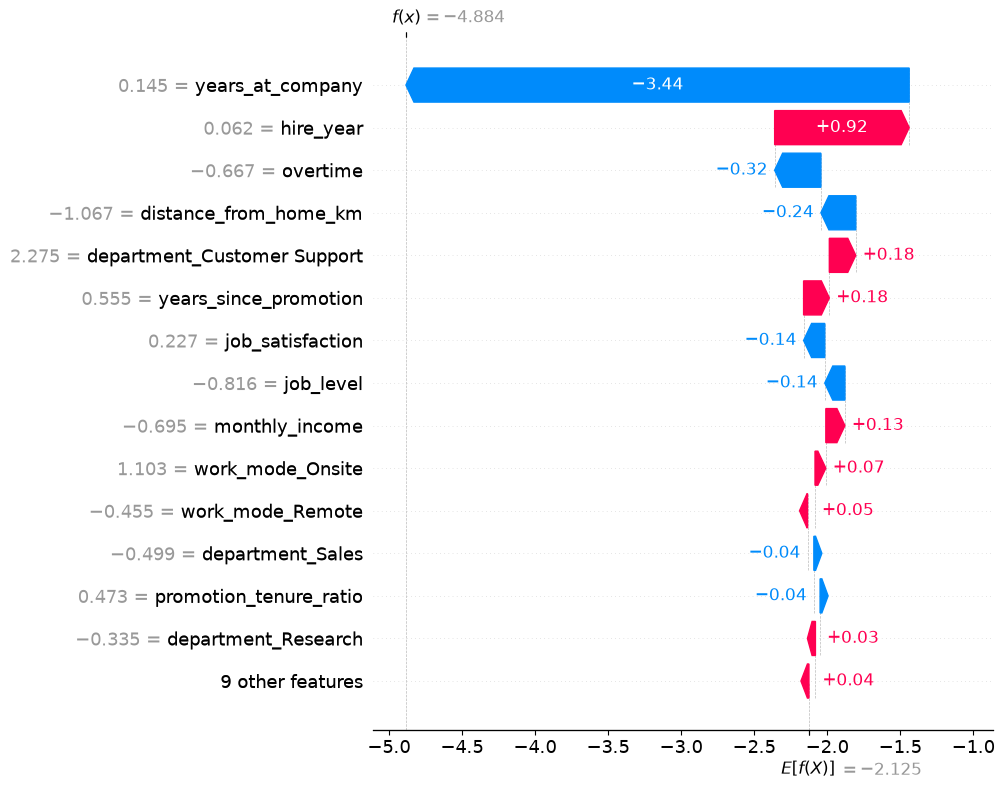

In [ ]:
X_val_transformed = logistic_model.named_steps["scaler"].transform(
    logistic_model.named_steps["imputer"].transform(X_val)
)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_val_transformed[0],
        feature_names=X_val.columns.tolist()
    ),
    max_display=15
#)

In [56]:
#Initialize the model saving process
import os
import joblib

os.makedirs("../models", exist_ok=True)

model_bundle = {
    "model": logistic_model,
    "threshold": 0.40,
    "features": X_train_new.columns.tolist()
}

joblib.dump(model_bundle, "../models/attrisense_model.pkl")

print("AttriSense model saved successfully!")

AttriSense model saved successfully!


In [57]:
loaded_bundle = joblib.load("../models/attrisense_model.pkl")

print("Saved items:", loaded_bundle.keys())
print("Threshold:", loaded_bundle["threshold"])
print("Number of features:", len(loaded_bundle["features"]))
print("Features:", loaded_bundle["features"])

Saved items: dict_keys(['model', 'threshold', 'features'])
Threshold: 0.4
Number of features: 23
Features: ['job_level', 'age', 'years_at_company', 'monthly_income', 'overtime', 'job_satisfaction', 'performance_rating', 'distance_from_home_km', 'years_since_promotion', 'department_Customer Support', 'department_Engineering', 'department_Finance', 'department_Human Resources', 'department_Marketing', 'department_Operations', 'department_Research', 'department_Sales', 'work_mode_Hybrid', 'work_mode_Onsite', 'work_mode_Remote', 'hire_year', 'promotion_tenure_ratio', 'overtime_tenure']


In [60]:
import joblib

# Transform training data using the existing fitted pipeline
X_background = logistic_model.named_steps["imputer"].transform(
    X_train_new
)

X_background = logistic_model.named_steps["scaler"].transform(
    X_background
)

# Keep a small representative sample
background_data = X_background[:100]

# Load the existing model bundle
model_bundle = joblib.load("../models/attrisense_model.pkl")

# Add SHAP background data
model_bundle["background_data"] = background_data

# Save the updated bundle
joblib.dump(
    model_bundle,
    "../models/attrisense_model.pkl"
)

print("SHAP background data saved successfully!")

SHAP background data saved successfully!


In [61]:
pip install shap

Note: you may need to restart the kernel to use updated packages.
